In [ ]:
# Importing Libraries

import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%pip install python-dotenv

In [2]:
# After downloading sqlalchemy and psycopg2-binary, this will hook it up to the referenced database (sql_course)

import os
from dotenv import load_dotenv, find_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

load_dotenv(find_dotenv())

engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME"),
))

In [3]:
# Testing connection to databse and use Python to call records

df = pd.read_sql(text("Select * FROM company_dim LIMIT 10;"), engine)
df.head()

,company_id,name,link,link_google,thumbnail
0,0,Cryptology,NaN,https://www.google.com/search?sca_esv=56842508...,https://encrypted-tbn0.gstatic.com/images?q=tb...
1,1,Edraak,NaN,https://www.google.com/search?hl=en&gl=us&q=Ed...,https://encrypted-tbn0.gstatic.com/images?q=tb...
2,2,Groupe ADP,http://www.groupeadp.fr/,https://www.google.com/search?gl=us&hl=en&q=Gr...,https://encrypted-tbn0.gstatic.com/images?q=tb...
3,3,Interactive Resources - iR,NaN,https://www.google.com/search?q=Interactive+Re...,https://encrypted-tbn0.gstatic.com/images?q=tb...
4,4,Cybernetic Search,NaN,https://www.google.com/search?gl=us&hl=en&q=Cy...,https://encrypted-tbn0.gstatic.com/images?q=tb...


In [4]:
# Introducing SQL query within Python command, assign object to Top Paying Jobs query

top_10_paying_jobs_query = """
SELECT
    job_id,
    job_title,
    job_location,
    job_schedule_type,
    salary_year_avg,
    job_posted_date,
    name AS company_name
FROM
    job_postings_fact
LEFT JOIN company_dim ON job_postings_fact.company_id = company_dim.company_id
WHERE
    job_title_short = 'Data Analyst' AND 
    job_location = 'Anywhere' AND
    salary_year_avg IS NOT NULL
ORDER BY salary_year_avg DESC
LIMIT 10;
"""
df_top_paying_jobs_query = pd.read_sql(text(top_10_paying_jobs_query), engine)
df_top_paying_jobs_query

,job_id,job_title,job_location,job_schedule_type,salary_year_avg,job_posted_date,company_name
0,226942,Data Analyst,Anywhere,Full-time,650000.0,2023-02-20 15:13:33,Mantys
1,547382,Director of Analytics,Anywhere,Full-time,336500.0,2023-08-23 12:04:42,Meta
2,552322,Associate Director- Data Insights,Anywhere,Full-time,255829.5,2023-06-18 16:03:12,AT&T
3,99305,"Data Analyst, Marketing",Anywhere,Full-time,232423.0,2023-12-05 20:00:40,Pinterest Job Advertisements
4,1021647,Data Analyst (Hybrid/Remote),Anywhere,Full-time,217000.0,2023-01-17 00:17:23,Uclahealthcareers
5,168310,Principal Data Analyst (Remote),Anywhere,Full-time,205000.0,2023-08-09 11:00:01,SmartAsset
6,731368,"Director, Data Analyst - HYBRID",Anywhere,Full-time,189309.0,2023-12-07 15:00:13,Inclusively
7,310660,"Principal Data Analyst, AV Performance Analysis",Anywhere,Full-time,189000.0,2023-01-05 00:00:25,Motional
8,1749593,Principal Data Analyst,Anywhere,Full-time,186000.0,2023-07-11 16:00:05,SmartAsset
9,387860,ERM Data Analyst,Anywhere,Full-time,184000.0,2023-06-09 08:01:04,Get It Recruit - Information Technology


In [6]:
# Expand search to top 20 jobs

df_top_20_paying_jobs_query = """
SELECT
    job_id,
    job_title,
    job_location,
    job_schedule_type,
    salary_year_avg,
    job_posted_date,
    name AS company_name
FROM
    job_postings_fact
LEFT JOIN company_dim ON job_postings_fact.company_id = company_dim.company_id
WHERE
    job_title_short = 'Data Analyst' AND 
    job_location = 'Anywhere' AND
    salary_year_avg IS NOT NULL
ORDER BY salary_year_avg DESC
LIMIT 20;
"""
df_top_20_paying_jobs_query = pd.read_sql(text(df_top_20_paying_jobs_query), engine)
df_top_20_paying_jobs_query

,job_id,job_title,job_location,job_schedule_type,salary_year_avg,job_posted_date,company_name
0,226942,Data Analyst,Anywhere,Full-time,650000.0,2023-02-20 15:13:33,Mantys
1,547382,Director of Analytics,Anywhere,Full-time,336500.0,2023-08-23 12:04:42,Meta
2,552322,Associate Director- Data Insights,Anywhere,Full-time,255829.5,2023-06-18 16:03:12,AT&T
3,99305,"Data Analyst, Marketing",Anywhere,Full-time,232423.0,2023-12-05 20:00:40,Pinterest Job Advertisements
4,1021647,Data Analyst (Hybrid/Remote),Anywhere,Full-time,217000.0,2023-01-17 00:17:23,Uclahealthcareers
5,168310,Principal Data Analyst (Remote),Anywhere,Full-time,205000.0,2023-08-09 11:00:01,SmartAsset
6,731368,"Director, Data Analyst - HYBRID",Anywhere,Full-time,189309.0,2023-12-07 15:00:13,Inclusively
7,310660,"Principal Data Analyst, AV Performance Analysis",Anywhere,Full-time,189000.0,2023-01-05 00:00:25,Motional
8,1749593,Principal Data Analyst,Anywhere,Full-time,186000.0,2023-07-11 16:00:05,SmartAsset
9,387860,ERM Data Analyst,Anywhere,Full-time,184000.0,2023-06-09 08:01:04,Get It Recruit - Information Technology


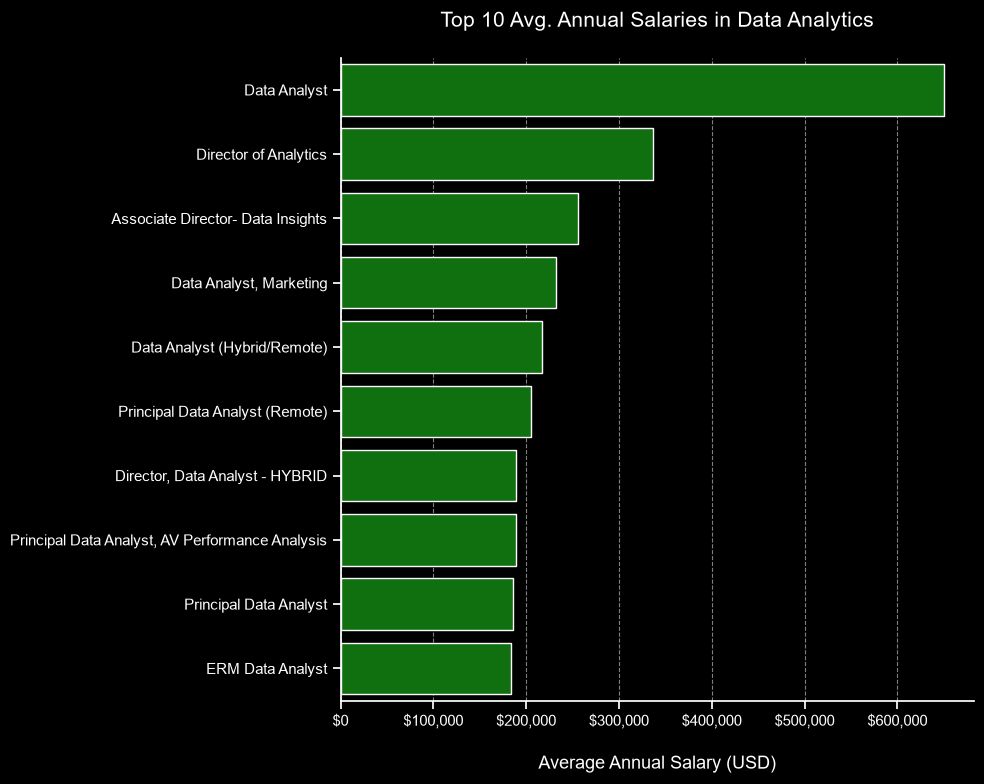

In [7]:
top_10_paying_jobs_query = """
SELECT
    job_id,
    job_title,
    job_location,
    job_schedule_type,
    salary_year_avg,
    job_posted_date,
    name AS company_name
FROM
    job_postings_fact
LEFT JOIN company_dim ON job_postings_fact.company_id = company_dim.company_id
WHERE
    job_title_short = 'Data Analyst' AND 
    job_location = 'Anywhere' AND
    salary_year_avg IS NOT NULL
ORDER BY salary_year_avg DESC
LIMIT 10;
"""
df_top_10_paying_jobs_query = pd.read_sql(text(top_10_paying_jobs_query), engine)
df_top_10_paying_jobs_query

# Visualize spread of annual average salary for 10 top-paying jobs

df_plot = (
    df_top_10_paying_jobs_query
    .dropna(subset=['salary_year_avg'])
    .nlargest(10, 'salary_year_avg')
)

# Format visual style
sns.set_theme(style='ticks')
plt.style.use('dark_background') 

fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(data=df_plot, x='salary_year_avg', y='job_title', color='green', ax=ax) # Format chart

# Format x-axis
ax.xaxis.grid(True, color='grey', linewidth=0.8, linestyle='--')
ax.set_axisbelow(True)  # places gridlines behind values
ax.xaxis.set_major_formatter(lambda x, _: f'${x:,.0f}')

sns.despine() # remove outer-most borders of plot
ax.set_title('Top 10 Avg. Annual Salaries in Data Analytics\n', fontsize=15) # inclusion of spacer ('\n') to separate title
ax.set_xlabel('\nAverage Annual Salary (USD)', fontsize=13) # inclusion of spacer ('\n') to separate title
ax.set_ylabel('')

plt.tight_layout()
plt.show()

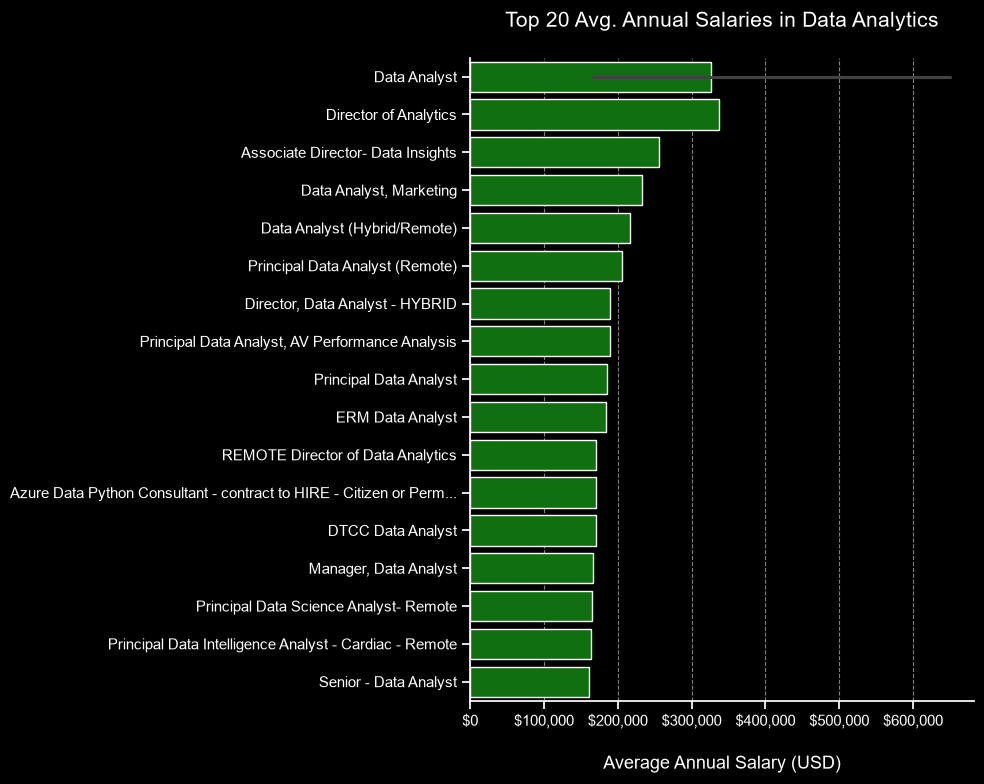

In [8]:
# Visualize spread of annual average salary for 20 top-paying jobs

df_plot = (
    df_top_20_paying_jobs_query
    .dropna(subset=['salary_year_avg'])
    .nlargest(20, 'salary_year_avg')
)

df_plot['label'] = df_plot['job_title'] + ' - ' + df_plot['company_name']

# Format visual style
sns.set_theme(style='ticks')
plt.style.use('dark_background') 

fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(data=df_plot, x='salary_year_avg', y='job_title', color='green', ax=ax) # Format chart

# Format x-axis
ax.xaxis.grid(True, color='grey', linewidth=0.8, linestyle='--')
ax.set_axisbelow(True)  # places gridlines behind values
ax.xaxis.set_major_formatter(lambda x, _: f'${x:,.0f}')

sns.despine() # remove outer-most borders of plot
ax.set_title('Top 20 Avg. Annual Salaries in Data Analytics\n', fontsize=15) # inclusion of spacer ('\n') to separate title
ax.set_xlabel('\nAverage Annual Salary (USD)', fontsize=13) # inclusion of spacer ('\n') to separate title
ax.set_ylabel('')

plt.tight_layout()
plt.show()

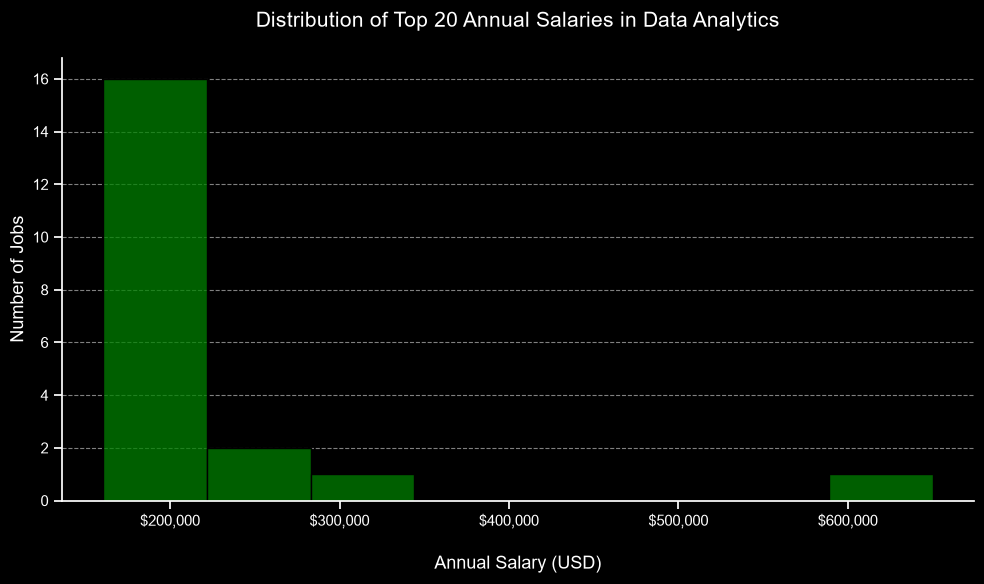

In [9]:
# Adjust the chart type to a histogram, showing number of jobs along salary range.

df_plot = (
    df_top_20_paying_jobs_query
    .dropna(subset=['salary_year_avg'])
    .nlargest(20, 'salary_year_avg')
    .copy()
)

sns.set_theme(style='ticks')
plt.style.use('dark_background')

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(data=df_plot, x='salary_year_avg', bins=8, color='green', edgecolor='black', ax=ax)

ax.yaxis.grid(True, color='grey', linewidth=0.8, linestyle='--')
ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(lambda x, _: f'${x:,.0f}')
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))

sns.despine()
ax.set_title('Distribution of Top 20 Annual Salaries in Data Analytics\n', fontsize=15)
ax.set_xlabel('\nAnnual Salary (USD)', fontsize=13)
ax.set_ylabel('Number of Jobs', fontsize=13)

plt.tight_layout()
plt.show()

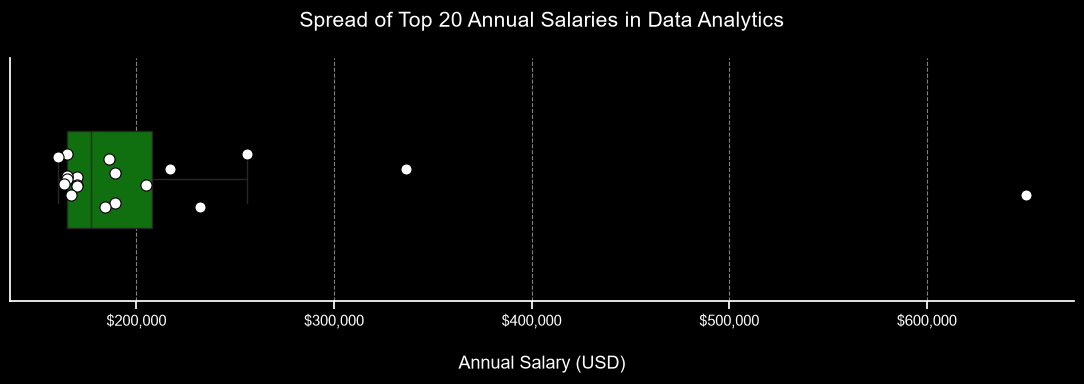

In [10]:
# Visualize top 20 paying jobs in a boxplot

df_plot = (
    df_top_20_paying_jobs_query
    .dropna(subset=['salary_year_avg'])
    .nlargest(20, 'salary_year_avg')
    .copy()
)

sns.set_theme(style='ticks')
plt.style.use('dark_background')

fig, ax = plt.subplots(figsize=(11, 4))

# Boxplot showing the spread (outlier markers hidden, since every point is drawn below)
sns.boxplot(data=df_plot, x='salary_year_avg', color='green', width=0.4,
            fliersize=0, ax=ax)

# Show each distinct salary as a dot
sns.stripplot(data=df_plot, x='salary_year_avg', color='white', edgecolor='black',
              linewidth=0.8, size=8, jitter=0.12, ax=ax)

ax.xaxis.grid(True, color='grey', linewidth=0.8, linestyle='--') # Formatting x-axis
ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(lambda x, _: f'${x:,.0f}') # Convert x-axis labels to consistent dollar amount increments (e.g. $300,000, $400,000)

sns.despine()
ax.set_title('Spread of Top 20 Annual Salaries in Data Analytics\n', fontsize=15) # Title
ax.set_xlabel('\nAnnual Salary (USD)', fontsize=13) # x-axis label
ax.set_ylabel('')
ax.set_yticks([])  # Remove y-axis due to single dimension

plt.tight_layout()
plt.show()